<a href="https://colab.research.google.com/github/SHIVARAMAN15/mayacardio-ppg-signal-analysis/blob/main/MayaCardio_PPG_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [15]:

from google.colab import files
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Upload the supplied JSON dataset
uploaded = files.upload()

# Identify the uploaded JSON file
json_name = next(
    name for name in uploaded if name.lower().endswith(".json")
)

with open(json_name, "r") as f:
    data = json.load(f)

# Read metadata from the dataset
fs = data["sampling_rate_hz"]
duration = data["duration_s"]
expected_samples = data["expected_samples_per_recording"]
recordings = data["recordings"]

print("Dataset:", json_name)
print("Sampling rate:", fs, "Hz")
print("Duration:", duration, "seconds")
print("Expected samples per recording:", expected_samples)
print("Number of recordings:", len(recordings))
print("Recording IDs:",
      [r["recording_id"] for r in recordings])


Saving MayaCardio_Signal_Processing_Case_Data_ppg.json to MayaCardio_Signal_Processing_Case_Data_ppg (1).json
Dataset: MayaCardio_Signal_Processing_Case_Data_ppg (1).json
Sampling rate: 200 Hz
Duration: 30 seconds
Expected samples per recording: 6000
Number of recordings: 5
Recording IDs: ['S1', 'S2', 'S3', 'S4', 'S5']


In [16]:

signals = {}
integrity_rows = []
packet_issues = []

for rec in recordings:
    rid = rec["recording_id"]
    packets = rec["packets"]

    # Reconstruct using the original sample indices.
    signal = np.full(expected_samples, np.nan)
    sample_counts = np.zeros(expected_samples, dtype=int)

    seen_sequences = []
    expected_packets = int(np.ceil(expected_samples / 100))

    for packet in packets:
        seq = packet["sequence"]
        start = packet["first_sample_index"]
        values = np.asarray(packet["values"], dtype=float)

        seen_sequences.append(seq)

        # Check declared count against actual values.
        if packet["sample_count"] != len(values):
            packet_issues.append({
                "recording": rid,
                "packet": seq,
                "issue": "Declared count differs from values",
            })

        # Check sequence-to-index consistency.
        if start != seq * 100:
            packet_issues.append({
                "recording": rid,
                "packet": seq,
                "issue": "Unexpected first sample index",
            })

        # Check nominal packet timestamp.
        expected_time = start / fs
        if not np.isclose(
            packet["nominal_first_sample_time_s"],
            expected_time,
            atol=1e-9
        ):
            packet_issues.append({
                "recording": rid,
                "packet": seq,
                "issue": "Nominal timestamp mismatch",
            })

        # Check for out-of-range samples and overlaps.
        for offset, value in enumerate(values):
            idx = start + offset

            if not 0 <= idx < expected_samples:
                packet_issues.append({
                    "recording": rid,
                    "packet": seq,
                    "issue": f"Sample index out of range: {idx}",
                })
                continue

            sample_counts[idx] += 1

            if sample_counts[idx] == 1:
                signal[idx] = value

    # Missing, duplicate and invalid values.
    missing_indices = np.where(sample_counts == 0)[0]
    duplicate_indices = np.where(sample_counts > 1)[0]
    invalid_values = int(np.sum(~np.isfinite(signal)))

    missing_sequences = sorted(
        set(range(expected_packets)) - set(seen_sequences)
    )
    duplicate_sequences = sorted(
        seq for seq in set(seen_sequences)
        if seen_sequences.count(seq) > 1
    )

    signals[rid] = signal

    integrity_rows.append({
        "Recording": rid,
        "Packets": len(packets),
        "Missing packet IDs": str(missing_sequences),
        "Duplicate packet IDs": str(duplicate_sequences),
        "Missing samples": len(missing_indices),
        "Overlapping samples": len(duplicate_indices),
        "Invalid samples": invalid_values,
        "Valid samples": int(np.isfinite(signal).sum()),
        "Min amplitude": np.nanmin(signal),
        "Max amplitude": np.nanmax(signal),
    })

integrity = pd.DataFrame(integrity_rows)

print("PACKET INTEGRITY REPORT")
display(integrity.round(4))

print("\nPACKET-LEVEL ISSUES")
if packet_issues:
    display(pd.DataFrame(packet_issues))
else:
    print("No packet-level issues detected.")


PACKET INTEGRITY REPORT


,Recording,Packets,Missing packet IDs,Duplicate packet IDs,Missing samples,Overlapping samples,Invalid samples,Valid samples,Min amplitude,Max amplitude
0,S1,60,[],[],0,0,0,6000,-0.2923,1.9897
1,S2,60,[],[],0,0,0,6000,-0.4294,2.2355
2,S3,60,[],[],0,0,0,6000,-0.7628,2.2553
3,S4,60,[],[],0,0,0,6000,-0.5234,2.2085
4,S5,58,"[20, 21]",[],200,0,200,5800,-0.2923,1.9897



PACKET-LEVEL ISSUES
No packet-level issues detected.


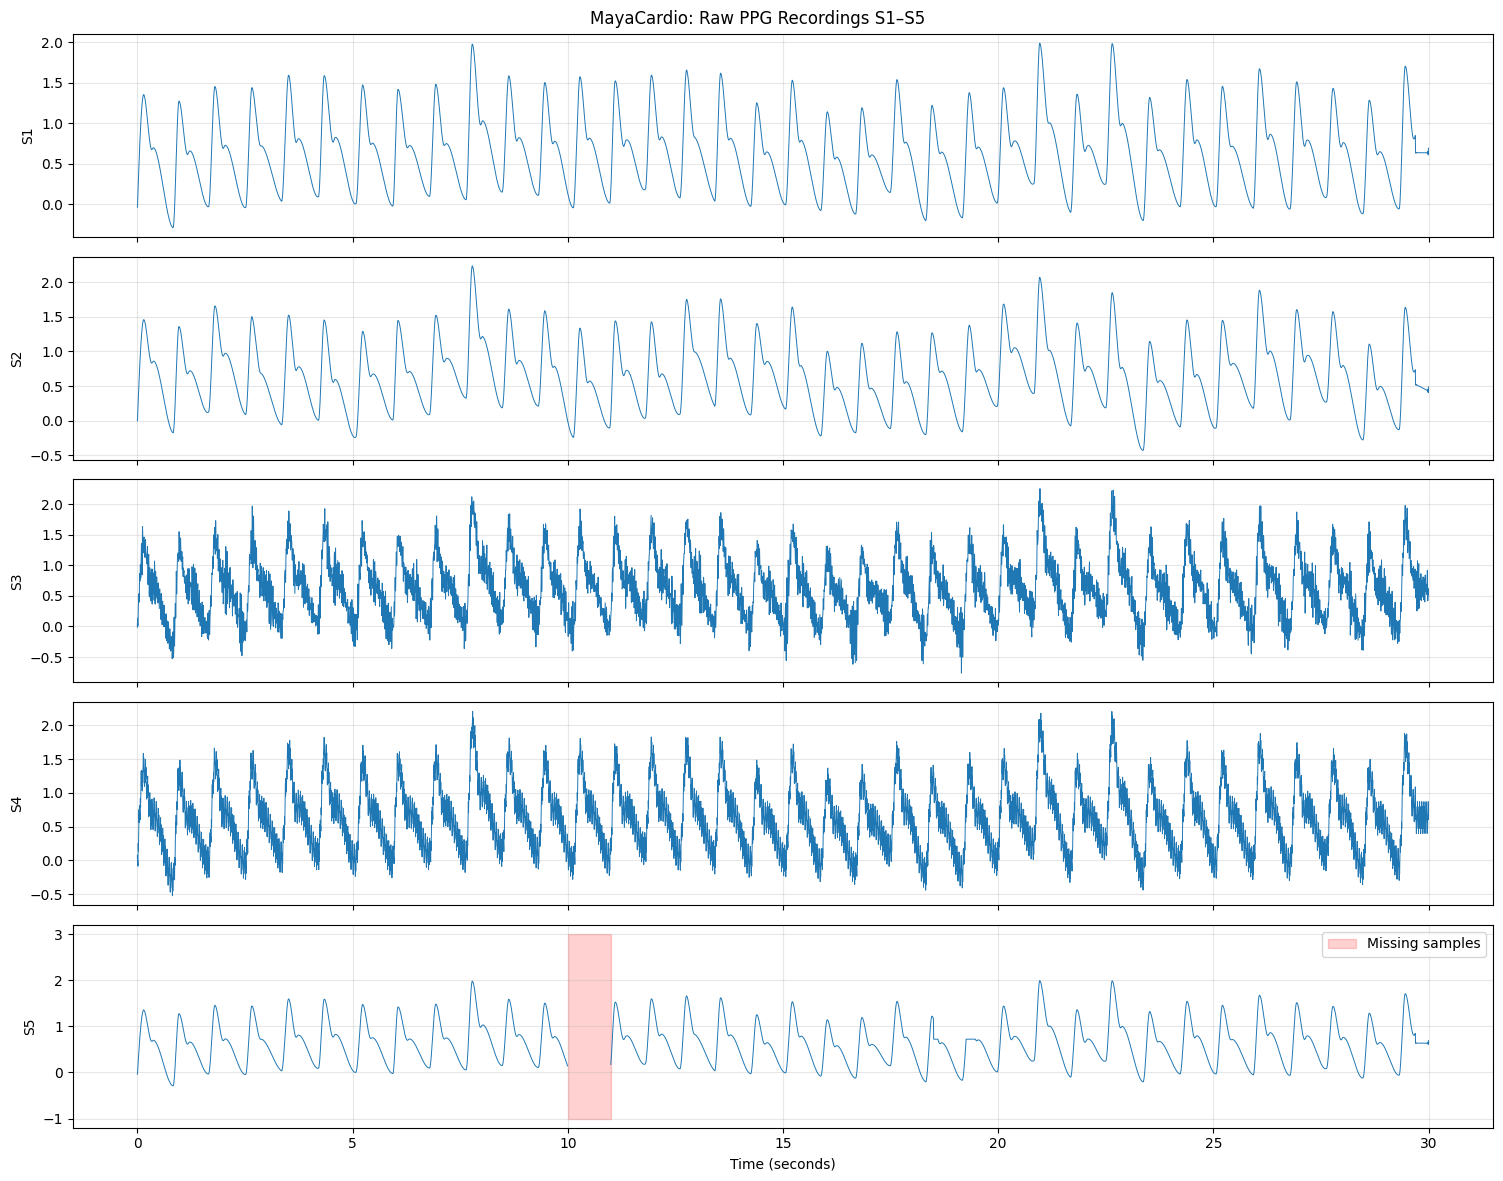

In [17]:

fs = data["sampling_rate_hz"]
t = np.arange(expected_samples) / fs

fig, axes = plt.subplots(
    5, 1, figsize=(15, 12), sharex=True
)

for ax, (rid, signal) in zip(axes, signals.items()):
    ax.plot(t, signal, linewidth=0.7)
    ax.set_ylabel(rid)
    ax.grid(True, alpha=0.3)

    # Highlight gaps without filling or interpolating them.
    missing = ~np.isfinite(signal)
    if missing.any():
        ax.fill_between(
            t, -1, 3, where=missing,
            color="red", alpha=0.18,
            label="Missing samples"
        )
        ax.legend(loc="upper right")

axes[-1].set_xlabel("Time (seconds)")
fig.suptitle("MayaCardio: Raw PPG Recordings S1–S5")
plt.tight_layout()
plt.show()


In [18]:

# Save the raw waveform figure
plt.savefig(
    "MayaCardio_Raw_PPG_Overview.png",
    dpi=200,
    bbox_inches="tight"
)

# Download the figure to your laptop
from google.colab import files
files.download("MayaCardio_Raw_PPG_Overview.png")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<Figure size 640x480 with 0 Axes>

In [19]:
corrected_rows = []

for rec in recordings:
    rid = rec["recording_id"]
    packets = rec["packets"]

    received_nonfinite = sum(
        np.sum(~np.isfinite(np.asarray(p["values"], dtype=float)))
        for p in packets
    )

    signal = signals[rid]

    corrected_rows.append({
        "Recording": rid,
        "Received packets": len(packets),
        "Missing samples": int(np.isnan(signal).sum()),
        "Non-finite received values": int(received_nonfinite),
        "Valid samples": int(np.isfinite(signal).sum())
    })

display(pd.DataFrame(corrected_rows))

,Recording,Received packets,Missing samples,Non-finite received values,Valid samples
0,S1,60,0,0,6000
1,S2,60,0,0,6000
2,S3,60,0,0,6000
3,S4,60,0,0,6000
4,S5,58,200,0,5800


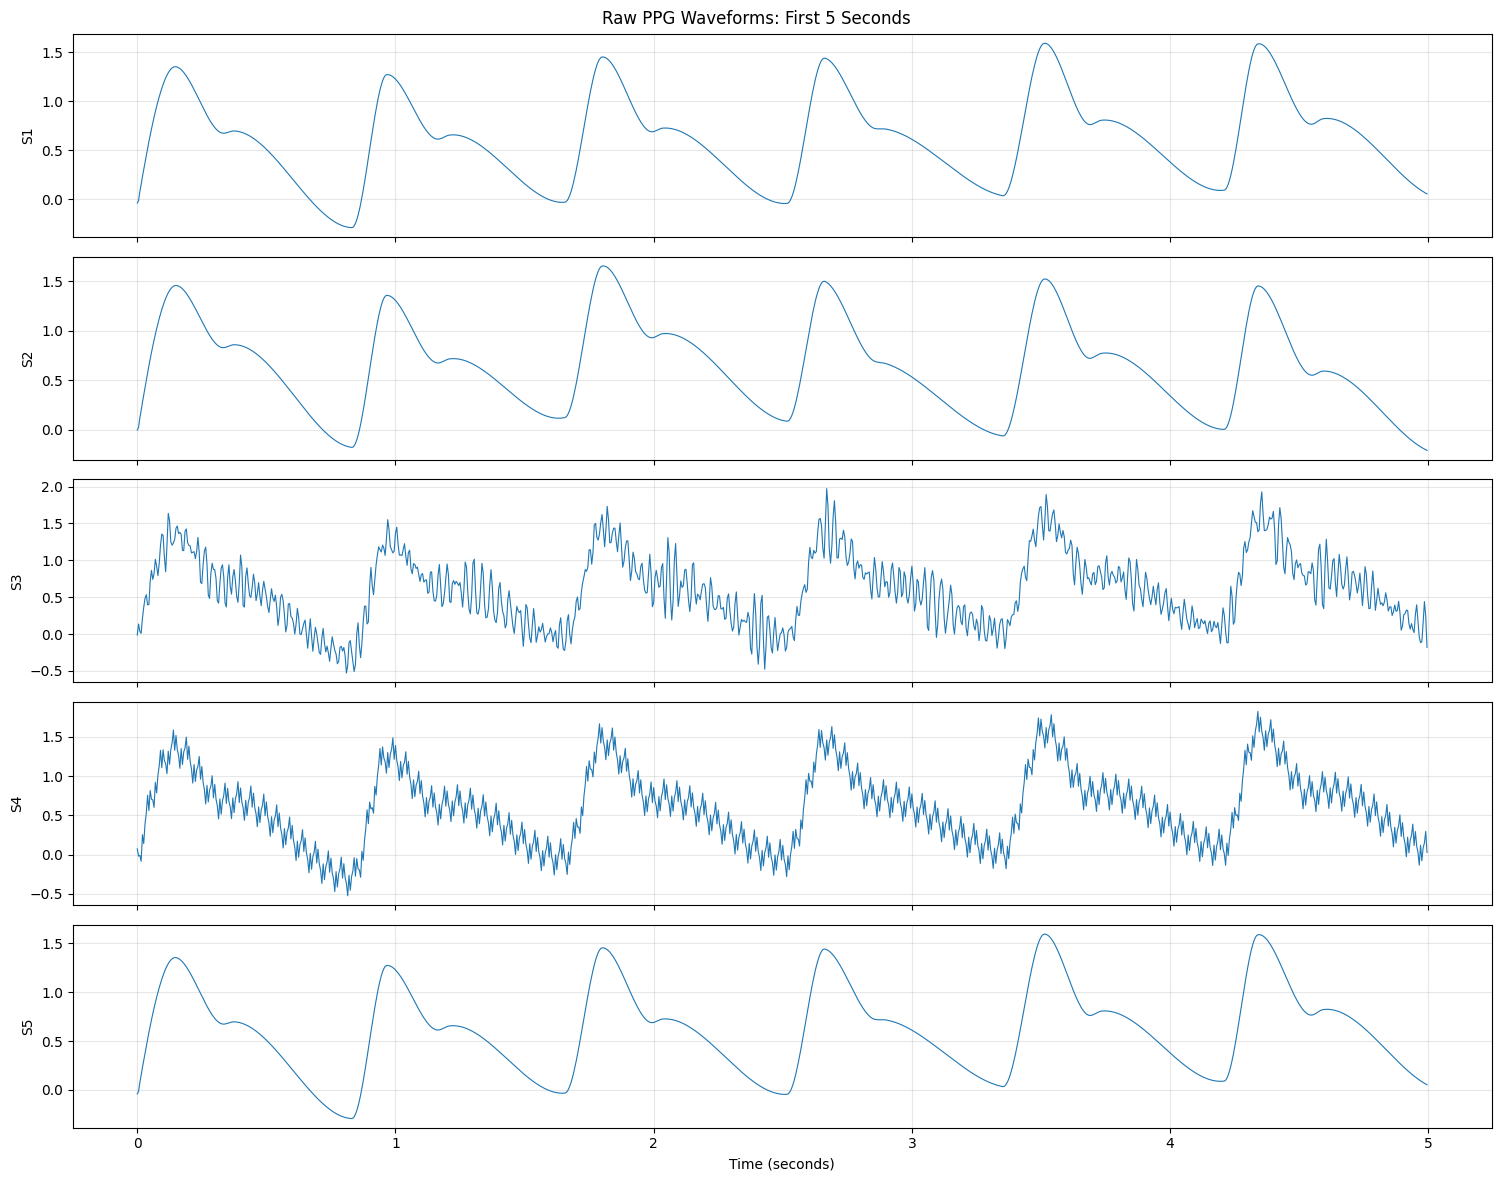

In [20]:
fig, axes = plt.subplots(5, 1, figsize=(15, 12), sharex=True)

# Inspect the first 5 seconds
start_time = 0
end_time = 5

for ax, (rid, signal) in zip(axes, signals.items()):
    start_idx = int(start_time * fs)
    end_idx = int(end_time * fs)

    ax.plot(
        t[start_idx:end_idx],
        signal[start_idx:end_idx],
        linewidth=0.8
    )

    ax.set_ylabel(rid)
    ax.grid(True, alpha=0.3)

axes[-1].set_xlabel("Time (seconds)")
fig.suptitle("Raw PPG Waveforms: First 5 Seconds")
plt.tight_layout()
plt.show()

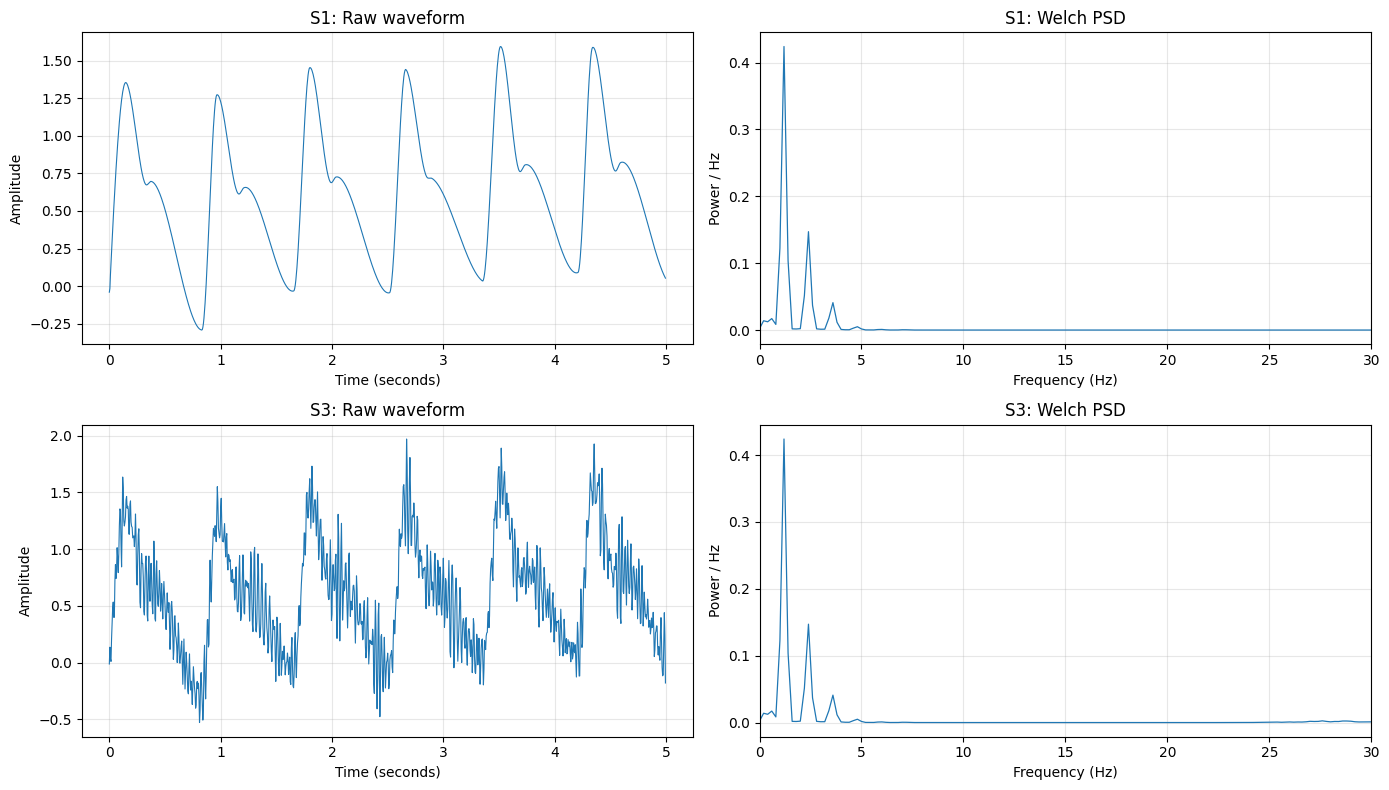

,Recording,Mean,Standard deviation,Difference standard deviation
0,S1,0.63483,0.45822,0.02718
1,S3,0.63480,0.48823,0.18905


In [21]:

from scipy.signal import welch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Use only recordings without missing samples for this comparison
selected = ["S1", "S3"]
results = []

fig, axes = plt.subplots(2, 2, figsize=(14, 8))

for i, rid in enumerate(selected):
    x = signals[rid]

    # Safety check: avoid calculations across missing data
    if not np.isfinite(x).all():
        print(f"{rid}: contains missing samples; skipping.")
        continue

    # Basic statistics on the raw, unmodified signal
    std_value = np.std(x)
    diff_std = np.std(np.diff(x))

    # Welch power spectral density
    freqs, psd = welch(
        x,
        fs=fs,
        nperseg=1000,
        noverlap=500
    )

    results.append({
        "Recording": rid,
        "Mean": np.mean(x),
        "Standard deviation": std_value,
        "Difference standard deviation": diff_std
    })

    # First 5 seconds
    n = int(5 * fs)
    axes[i, 0].plot(np.arange(n) / fs, x[:n], linewidth=0.8)
    axes[i, 0].set_title(f"{rid}: Raw waveform")
    axes[i, 0].set_xlabel("Time (seconds)")
    axes[i, 0].set_ylabel("Amplitude")
    axes[i, 0].grid(True, alpha=0.3)

    # Frequency content up to 30 Hz
    axes[i, 1].plot(freqs, psd, linewidth=0.9)
    axes[i, 1].set_xlim(0, 30)
    axes[i, 1].set_title(f"{rid}: Welch PSD")
    axes[i, 1].set_xlabel("Frequency (Hz)")
    axes[i, 1].set_ylabel("Power / Hz")
    axes[i, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

display(pd.DataFrame(results).round(5))


In [22]:

from scipy.signal import welch
import numpy as np
import pandas as pd

bands = [
    ("0.5–2 Hz", 0.5, 2.0),
    ("2–5 Hz", 2.0, 5.0),
    ("5–15 Hz", 5.0, 15.0),
    ("15–30 Hz", 15.0, 30.0),
]

band_rows = []

for rid in ["S1", "S3"]:
    x = signals[rid]

    freqs, psd = welch(
        x,
        fs=fs,
        nperseg=1000,
        noverlap=500
    )

    row = {"Recording": rid}

    for name, low, high in bands:
        mask = (freqs >= low) & (freqs < high)
        power = np.trapezoid(psd[mask], freqs[mask])
        row[name] = power

    band_rows.append(row)

band_table = pd.DataFrame(band_rows).set_index("Recording")
display(band_table.round(6))

# Compare the percentage of measured band power in each band
percentage_table = band_table.div(
    band_table.sum(axis=1), axis=0
) * 100

print("Percentage of measured power in the selected bands:")
display(percentage_table.round(2))


,0.5–2 Hz,2–5 Hz,5–15 Hz,15–30 Hz
Recording,,,,
S1,0.134031,0.063676,0.000977,0.000003
S3,0.134031,0.063676,0.000977,0.006343


Percentage of measured power in the selected bands:


,0.5–2 Hz,2–5 Hz,5–15 Hz,15–30 Hz
Recording,,,,
S1,67.46,32.05,0.49,0.00
S3,65.37,31.06,0.48,3.09


,Component,S1 standard deviation,S3 standard deviation,S1-S3 correlation
0,Below 5 Hz,0.453619,0.453589,0.999995
1,Above 15 Hz,0.002787,0.168289,0.025393


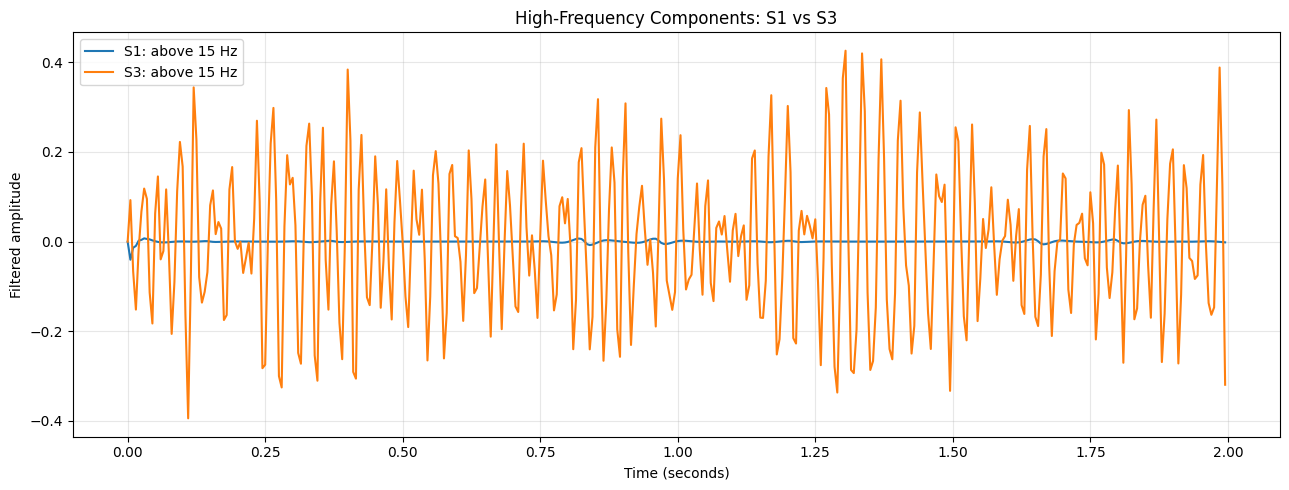

In [23]:

from scipy.signal import butter, sosfiltfilt
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

s1 = signals["S1"]
s3 = signals["S3"]

# Separate low- and high-frequency components for comparison
sos_low = butter(4, 5, btype="lowpass", fs=fs, output="sos")
sos_high = butter(4, 15, btype="highpass", fs=fs, output="sos")

s1_low = sosfiltfilt(sos_low, s1)
s3_low = sosfiltfilt(sos_low, s3)
s1_high = sosfiltfilt(sos_high, s1)
s3_high = sosfiltfilt(sos_high, s3)

comparison = pd.DataFrame([
    {
        "Component": "Below 5 Hz",
        "S1 standard deviation": np.std(s1_low),
        "S3 standard deviation": np.std(s3_low),
        "S1-S3 correlation": np.corrcoef(s1_low, s3_low)[0, 1]
    },
    {
        "Component": "Above 15 Hz",
        "S1 standard deviation": np.std(s1_high),
        "S3 standard deviation": np.std(s3_high),
        "S1-S3 correlation": np.corrcoef(s1_high, s3_high)[0, 1]
    }
])

display(comparison.round(6))

# Plot the high-frequency components over the first 2 seconds
n = int(2 * fs)
time = np.arange(n) / fs

plt.figure(figsize=(13, 5))
plt.plot(time, s1_high[:n], label="S1: above 15 Hz")
plt.plot(time, s3_high[:n], label="S3: above 15 Hz")
plt.xlabel("Time (seconds)")
plt.ylabel("Filtered amplitude")
plt.title("High-Frequency Components: S1 vs S3")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


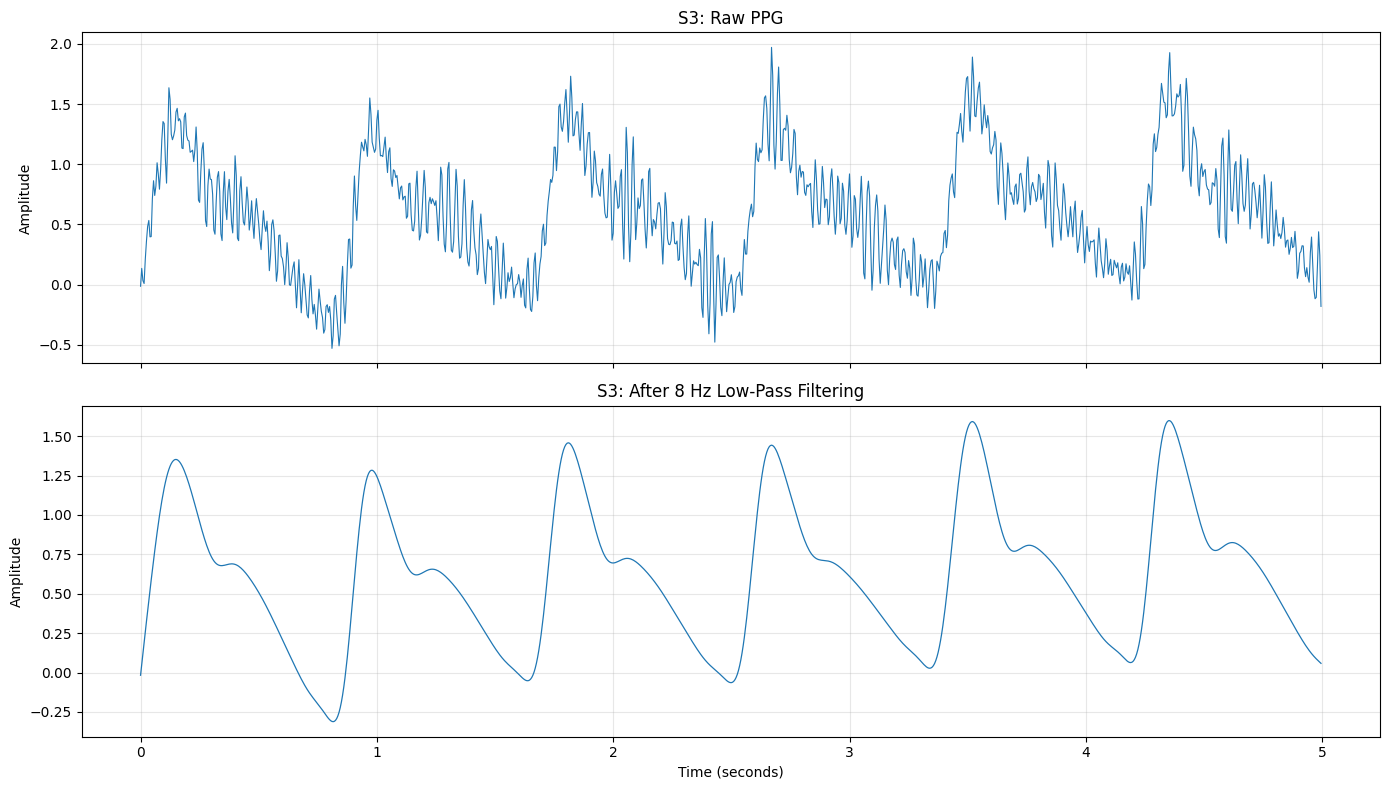

Raw standard deviation: 0.488225
Filtered standard deviation: 0.457763
Raw first-difference SD: 0.189055
Filtered first-difference SD: 0.026712


In [24]:

from scipy.signal import butter, sosfiltfilt
import numpy as np
import matplotlib.pyplot as plt

x = signals["S3"]
time = np.arange(len(x)) / fs

# Experimental mitigation: fourth-order low-pass filter at 8 Hz
cutoff_hz = 8.0
sos = butter(4, cutoff_hz, btype="lowpass", fs=fs, output="sos")
filtered = sosfiltfilt(sos, x)

# Compare the same interval before and after filtering
n = int(5 * fs)

fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

axes[0].plot(time[:n], x[:n], linewidth=0.8)
axes[0].set_title("S3: Raw PPG")
axes[0].set_ylabel("Amplitude")
axes[0].grid(True, alpha=0.3)

axes[1].plot(time[:n], filtered[:n], linewidth=0.9)
axes[1].set_title("S3: After 8 Hz Low-Pass Filtering")
axes[1].set_xlabel("Time (seconds)")
axes[1].set_ylabel("Amplitude")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("Raw standard deviation:", round(float(np.std(x)), 6))
print("Filtered standard deviation:", round(float(np.std(filtered)), 6))
print("Raw first-difference SD:", round(float(np.std(np.diff(x))), 6))
print("Filtered first-difference SD:", round(float(np.std(np.diff(filtered))), 6))


Raw peak count: 6
Filtered peak count: 6


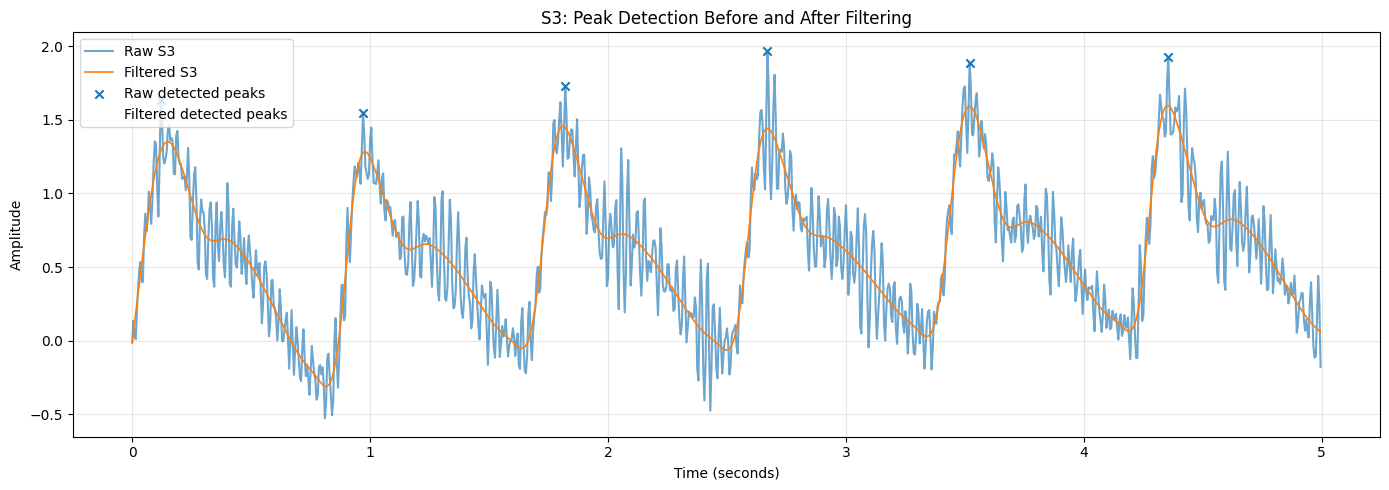

,Filtered peak time (s),Raw peak time (s),Timing difference (ms),Raw height,Filtered height,Raw width (s),Filtered width (s),Raw window area,Filtered window area,Match
0,0.15,0.120,30.0,1.6355,1.3523,0.1631,0.3700,0.3215,0.3234,Yes
1,0.98,0.970,10.0,1.5507,1.2836,0.2038,0.3797,0.2499,0.2484,Yes
2,1.81,1.820,-10.0,1.7312,1.4577,0.2417,0.2647,0.3191,0.3197,Yes
3,2.67,2.670,0.0,1.9708,1.4427,0.1765,0.2581,0.3215,0.3210,Yes
4,3.52,3.520,0.0,1.8904,1.5925,0.1765,0.2261,0.3622,0.3631,Yes
5,4.35,4.355,-5.0,1.9272,1.5982,0.1606,0.2384,0.3630,0.3620,Yes


In [25]:

from scipy.signal import find_peaks, peak_widths
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Analyze the same 5-second interval
raw = signals["S3"][:int(5 * fs)]
filt = filtered[:int(5 * fs)]
time = np.arange(len(raw)) / fs

# Use the same minimum peak spacing and prominence for both
min_distance = int(0.45 * fs)
prominence = 0.40

raw_peaks, _ = find_peaks(
    raw, distance=min_distance, prominence=prominence
)
filt_peaks, _ = find_peaks(
    filt, distance=min_distance, prominence=prominence
)

print("Raw peak count:", len(raw_peaks))
print("Filtered peak count:", len(filt_peaks))

# Plot both signals and detected peaks
plt.figure(figsize=(14, 5))
plt.plot(time, raw, alpha=0.65, label="Raw S3")
plt.plot(time, filt, linewidth=1.2, label="Filtered S3")
plt.scatter(time[raw_peaks], raw[raw_peaks],
            marker="x", label="Raw detected peaks")
plt.scatter(time[filt_peaks], filt[filt_peaks],
            marker="o", facecolors="none",
            label="Filtered detected peaks")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.title("S3: Peak Detection Before and After Filtering")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# Calculate widths at half prominence
raw_widths = peak_widths(raw, raw_peaks, rel_height=0.5)[0] / fs
filt_widths = peak_widths(filt, filt_peaks, rel_height=0.5)[0] / fs

# Compare each filtered peak with the nearest raw peak
rows = []

for j, p_f in enumerate(filt_peaks):
    if len(raw_peaks) == 0:
        break

    nearest_index = np.argmin(np.abs(raw_peaks - p_f))
    p_r = raw_peaks[nearest_index]
    timing_difference = (p_f - p_r) / fs

    # Only pair peaks that are within 150 ms
    if abs(timing_difference) > 0.15:
        rows.append({
            "Filtered peak time (s)": p_f / fs,
            "Raw peak time (s)": p_r / fs,
            "Timing difference (ms)": timing_difference * 1000,
            "Raw height": raw[p_r],
            "Filtered height": filt[p_f],
            "Raw width (s)": raw_widths[nearest_index],
            "Filtered width (s)": filt_widths[j],
            "Match": "No: timing difference >150 ms"
        })
        continue

    # Integrate amplitude in the same fixed window around the filtered peak
    left = max(0, p_f - int(0.20 * fs))
    right = min(len(raw), p_f + int(0.20 * fs) + 1)

    raw_area = np.trapezoid(raw[left:right], dx=1/fs)
    filtered_area = np.trapezoid(filt[left:right], dx=1/fs)

    rows.append({
        "Filtered peak time (s)": p_f / fs,
        "Raw peak time (s)": p_r / fs,
        "Timing difference (ms)": timing_difference * 1000,
        "Raw height": raw[p_r],
        "Filtered height": filt[p_f],
        "Raw width (s)": raw_widths[nearest_index],
        "Filtered width (s)": filt_widths[j],
        "Raw window area": raw_area,
        "Filtered window area": filtered_area,
        "Match": "Yes"
    })

display(pd.DataFrame(rows).round(4))


In [26]:

from scipy.signal import find_peaks
import numpy as np
import pandas as pd

raw = signals["S3"]
filt = filtered

# Use consistent detection settings for both signals
min_distance = int(0.45 * fs)
prominence = 0.40

raw_peaks, _ = find_peaks(
    raw, distance=min_distance, prominence=prominence
)
filt_peaks, _ = find_peaks(
    filt, distance=min_distance, prominence=prominence
)

# Match each filtered peak to the nearest raw peak,
# allowing each raw peak to be matched only once
unused_raw = set(range(len(raw_peaks)))
matches = []

for fi in filt_peaks:
    candidates = list(unused_raw)

    if not candidates:
        break

    nearest = min(
        candidates,
        key=lambda j: abs(raw_peaks[j] - fi)
    )

    delta_ms = (fi - raw_peaks[nearest]) / fs * 1000

    if abs(delta_ms) <= 150:
        matches.append({
            "Raw peak time (s)": raw_peaks[nearest] / fs,
            "Filtered peak time (s)": fi / fs,
            "Timing difference (ms)": delta_ms
        })
        unused_raw.remove(nearest)

matched_raw = len(matches)
unmatched_raw = len(raw_peaks) - matched_raw
unmatched_filtered = len(filt_peaks) - matched_raw

print("Recording duration:", len(raw) / fs, "seconds")
print("Raw peak count:", len(raw_peaks))
print("Filtered peak count:", len(filt_peaks))
print("Matched peaks:", matched_raw)
print("Unmatched raw peaks:", unmatched_raw)
print("Unmatched filtered peaks:", unmatched_filtered)

if matches:
    timing = np.array([
        m["Timing difference (ms)"] for m in matches
    ])

    print("Median absolute timing difference (ms):",
          round(float(np.median(np.abs(timing))), 2))
    print("Maximum absolute timing difference (ms):",
          round(float(np.max(np.abs(timing))), 2))

    display(pd.DataFrame(matches).round(3))


Recording duration: 30.0 seconds
Raw peak count: 37
Filtered peak count: 36
Matched peaks: 36
Unmatched raw peaks: 1
Unmatched filtered peaks: 0
Median absolute timing difference (ms): 15.0
Maximum absolute timing difference (ms): 45.0


,Raw peak time (s),Filtered peak time (s),Timing difference (ms)
0,0.120,0.150,30.0
1,0.970,0.980,10.0
2,1.820,1.810,-10.0
3,2.670,2.670,0.0
4,3.520,3.520,0.0
5,4.355,4.350,-5.0
6,5.225,5.240,15.0
7,6.070,6.070,0.0
8,6.955,6.940,-15.0
9,7.770,7.790,20.0


Unmatched raw peak times (seconds): [np.float64(29.97)]


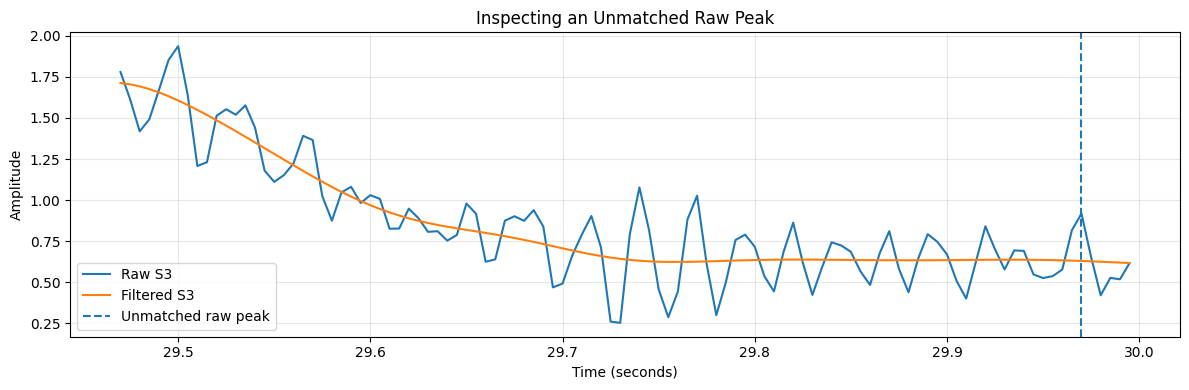

In [27]:

# Recreate the peak matching and identify unmatched raw peaks
raw = signals["S3"]
filt = filtered

raw_peaks, _ = find_peaks(
    raw, distance=int(0.45 * fs), prominence=0.40
)
filt_peaks, _ = find_peaks(
    filt, distance=int(0.45 * fs), prominence=0.40
)

unmatched_raw_peaks = []

for rp in raw_peaks:
    nearest_filtered = (
        np.min(np.abs(filt_peaks - rp))
        if len(filt_peaks) else np.inf
    )

    if nearest_filtered / fs > 0.150:
        unmatched_raw_peaks.append(rp)

print("Unmatched raw peak times (seconds):",
      [round(p / fs, 3) for p in unmatched_raw_peaks])

# Plot the region around each unmatched peak
for rp in unmatched_raw_peaks:
    left = max(0, rp - int(0.5 * fs))
    right = min(len(raw), rp + int(0.5 * fs))

    plt.figure(figsize=(12, 4))
    plt.plot(np.arange(left, right) / fs, raw[left:right],
             label="Raw S3")
    plt.plot(np.arange(left, right) / fs, filt[left:right],
             label="Filtered S3")
    plt.axvline(rp / fs, linestyle="--",
                label="Unmatched raw peak")
    plt.xlabel("Time (seconds)")
    plt.ylabel("Amplitude")
    plt.title("Inspecting an Unmatched Raw Peak")
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()
